In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

DATA = "house-prices-advanced-regression-techniques/"
train = pd.read_csv(DATA + "train.csv")
test = pd.read_csv(DATA + "test.csv")
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
skewness: 1.8828757597682129


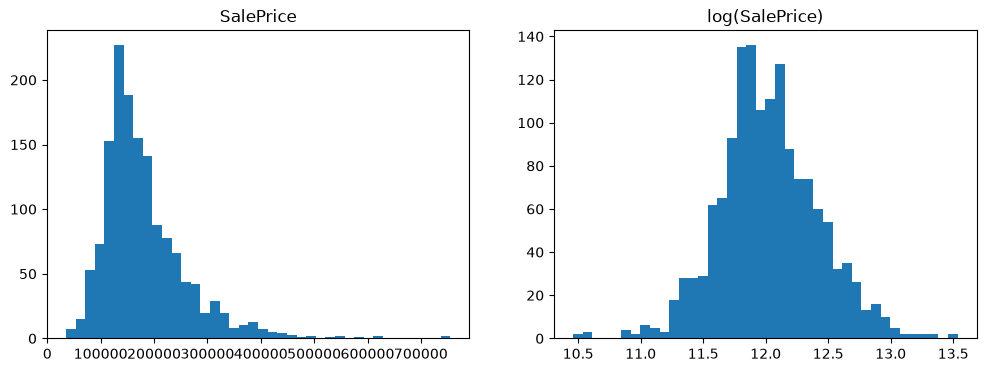

In [2]:
print(train["SalePrice"].describe())
print("skewness:", train["SalePrice"].skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["SalePrice"], bins=40)
axes[0].set_title("SalePrice")
axes[1].hist(np.log1p(train["SalePrice"]), bins=40)
axes[1].set_title("log(SalePrice)")
plt.show()

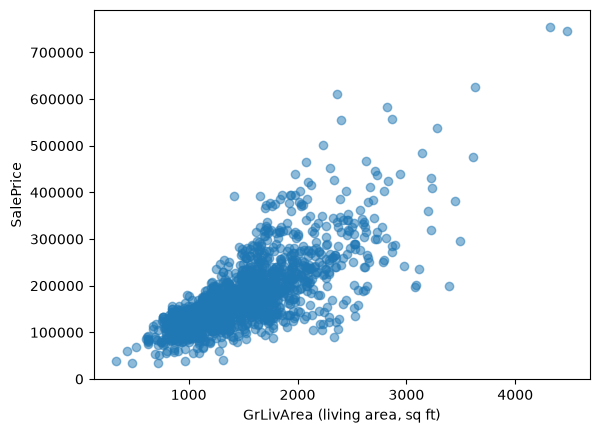

In [3]:
outliers = train[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)]
train = train.drop(outliers.index)

plt.scatter(train["GrLivArea"], train["SalePrice"], alpha=0.5)
plt.xlabel("GrLivArea (living area, sq ft)")
plt.ylabel("SalePrice")
plt.show()

In [4]:
train_rows = len(train)
if "SalePrice" in train:
    sale_price = train['SalePrice'].reset_index(drop=True)  
    train = train.drop('SalePrice',axis=1)
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


In [5]:
all_data = pd.concat([train,test],ignore_index=True)
missing = all_data.isnull().sum().sort_values(ascending=False)
todo_list = missing[missing > 0]
columns_in_list = len(todo_list)
print(columns_in_list)
todo_list.head()

34


PoolQC         2908
MiscFeature    2812
Alley          2719
Fence          2346
MasVnrType     1766
dtype: int64

In [6]:

none_cols = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual",
    "GarageCond", "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]

for c in none_cols:
    all_data[c] = all_data[c].fillna("None")

zero_cols = [
    "GarageYrBlt", "GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2",
    "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "MasVnrArea",
]
for c in zero_cols:
    all_data[c] = all_data[c].fillna(0)

# Neighborhood-median imputation for lot frontage
all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median())
)

mode_cols = [
    "MSZoning", "Utilities", "Exterior1st", "Exterior2nd",
    "KitchenQual", "Electrical", "Functional", "SaleType",
]

for c in mode_cols:
    val = all_data[c].mode()[0]
    all_data[c]= all_data[c].fillna(val)
    

missing = all_data.isnull().sum().sort_values(ascending=False)
todo_list = missing[missing > 0]
columns_in_list = len(todo_list)
print(columns_in_list)


0


In [7]:
all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

In [8]:
qual_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
          "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

qual_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

for c in qual_cols:
    all_data[c]= all_data[c].fillna("None").map(qual_map).fillna(0)

all_data["FireplaceQu"].value_counts(dropna=False)

FireplaceQu
0    1420
4     742
3     592
2      74
1      46
5      43
Name: count, dtype: int64

In [9]:
all_encoded = pd.get_dummies(all_data)
if "Id" in all_encoded:
    all_id = all_encoded["Id"]
    all_encoded = all_encoded.drop("Id",axis=1)
all_encoded

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,ExterQual,ExterCond,BsmtQual,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,65.0,8450,7,5,2003,2003,196.0,4,3,4,...,False,False,False,True,False,False,False,False,True,False
1,80.0,9600,6,8,1976,1976,0.0,3,3,4,...,False,False,False,True,False,False,False,False,True,False
2,68.0,11250,7,5,2001,2002,162.0,4,3,4,...,False,False,False,True,False,False,False,False,True,False
3,60.0,9550,7,5,1915,1970,0.0,3,3,3,...,False,False,False,True,True,False,False,False,False,False
4,84.0,14260,8,5,2000,2000,350.0,4,3,4,...,False,False,False,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2912,21.0,1936,4,7,1970,1970,0.0,3,3,3,...,False,False,False,True,False,False,False,False,True,False
2913,21.0,1894,4,5,1970,1970,0.0,3,3,3,...,False,False,False,True,True,False,False,False,False,False
2914,160.0,20000,5,7,1960,1996,0.0,3,3,3,...,False,False,False,True,True,False,False,False,False,False
2915,62.0,10441,5,5,1992,1992,0.0,3,3,4,...,False,False,False,True,False,False,False,False,True,False


In [10]:
X_train = all_encoded.iloc[:train_rows]
X_test = all_encoded.iloc[train_rows:].reset_index(drop=True)
test_id = all_id.iloc[train_rows:]
log_price = np.log1p(sale_price)
X_tr, X_val, Y_tr, Y_val = train_test_split(X_train,log_price,test_size=0.2,random_state=42)

In [11]:
model = LinearRegression()
model.fit(X_tr,Y_tr)
pred_val = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(Y_val,pred_val))
r2 = r2_score(Y_val,pred_val)

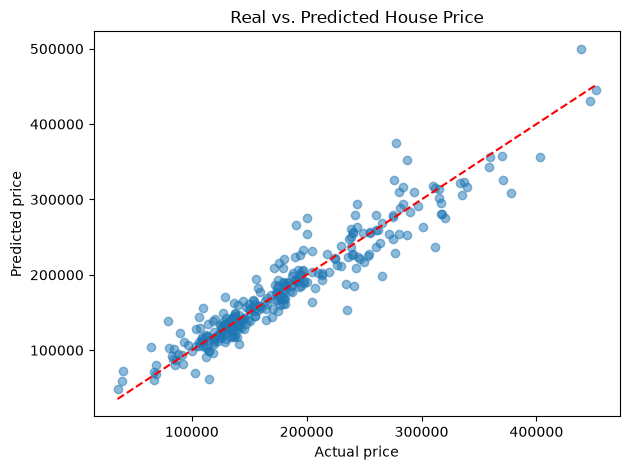

In [12]:
real_price = np.expm1(Y_val)
pred_price = np.expm1(pred_val)
plt.scatter(real_price,pred_price,alpha=0.5)
min_real_price = min(real_price)
max_real_price = max(real_price)
plt.plot([min_real_price,max_real_price],[min_real_price,max_real_price],color="red",linestyle="dashed")
plt.title("Real vs. Predicted House Price")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.tight_layout()
plt.savefig("real_vs_predicted.png")
plt.show()

In [13]:
final_model = LinearRegression()
final_model.fit(X_train, log_price)

pred_test_log = final_model.predict(X_test)
pred_test = np.expm1(pred_test_log)

submission = pd.DataFrame({
    "Id": test_id.values,
    "SalePrice": pred_test
})

submission.to_csv("submission.csv", index=False)

submission.head()

,Id,SalePrice
0,1461,119146.296494
1,1462,148742.392479
2,1463,178842.430728
3,1464,201676.828945
4,1465,198949.581643
